In [3]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\taper\anaconda3\envs\complexwaveforms\python.exe
3.11.15 | packaged by Anaconda, Inc. | (main, Jun 11 2026, 15:12:53) [MSC v.1942 64 bit (AMD64)]


In [2]:
import numpy as np
print("NumPy OK")

import sounddevice as sd
print("Sounddevice OK")

NumPy OK
Sounddevice OK


In [3]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import sounddevice as sd
from scipy.io.wavfile import write
from pathlib import Path

In [5]:
FS = 44100
DURATION = 1.5
AMPLITUDE = 0.8

BASE_FREQ = 80

In [6]:
def play_signal(signal):
    signal = signal / np.max(np.abs(signal))
    sd.play(signal, FS)
    sd.wait()

In [7]:
def save_signal(signal, filename):
    
    signal = signal / np.max(np.abs(signal))
    
    write(
        filename,
        FS,
        np.int16(signal * 32767)
    )

In [8]:
def generate_complex_tone(
    n_tones=2,
    ifi=100,
    duration=1 ,
    base_freq=80
):
    
    t = np.linspace(
        0,
        duration,
        int(FS*duration),
        endpoint=False
    )
    
    signal = np.zeros_like(t)
    
    for i in range(n_tones):
        
        freq = base_freq + i*ifi
        
        signal += np.sin(
            2*np.pi*freq*t
        )
    
    signal = signal / np.max(np.abs(signal))
    
    return signal

In [10]:
sig = generate_complex_tone(
    n_tones=2,
    ifi=100
)

play_signal(sig)

In [11]:
sig = generate_complex_tone(
    n_tones=3,
    ifi=100
)

play_signal(sig)

In [12]:
sig = generate_complex_tone(
    n_tones=4,
    ifi=100
)

play_signal(sig)

In [13]:
sig = generate_complex_tone(
    n_tones=3,
    ifi=50
)

play_signal(sig)

In [14]:
sig = generate_complex_tone(
    n_tones=3,
    ifi=50
)

play_signal(sig)

In [15]:
sig = generate_complex_tone(
    n_tones=3,
    ifi=100
)

play_signal(sig)

In [16]:
sig = generate_complex_tone(
    n_tones=3,
    ifi=150
)

play_signal(sig)

In [17]:
def apply_am(
    signal,
    depth=0.3,
    am_freq=10
):
    
    t = np.linspace(
        0,
        len(signal)/FS,
        len(signal),
        endpoint=False
    )
    
    envelope = (
        1 +
        depth *
        np.sin(2*np.pi*am_freq*t)
    )
    
    return signal * envelope

In [18]:
base = generate_complex_tone(
    n_tones=3,
    ifi=100
)

In [19]:
play_signal(
    apply_am(base,0.0)
)

In [26]:
play_signal(
    apply_am(base,0.3)
)

In [27]:
play_signal(
    apply_am(base,0.6)
)

In [28]:
play_signal(
    apply_am(base,0.9)
)

In [96]:
def apply_attack(
    signal,
    attack_ms=100
):
    
    attack_samples = int(
        attack_ms/1000 * FS
    )
    
    envelope = np.ones(
        len(signal)
    )
    
    envelope[:attack_samples] = np.linspace(
        0,
        1,
        attack_samples
    )
    
    return signal * envelope

In [97]:
base = generate_complex_tone(
    n_tones=3,
    ifi=100
)

In [106]:
play_signal(
    apply_attack(base,20)
)

In [105]:
play_signal(
    apply_attack(base,100)
)

In [104]:
play_signal(
    apply_attack(base,500)
)

In [107]:
sig = generate_complex_tone(
    n_tones=3,
    ifi=100,
    duration=5
)

play_signal(sig)

In [48]:
def play_signal(signal):

    signal = signal / np.max(np.abs(signal))

    sd.play(signal, FS)

    sd.wait()

    sd.stop()

In [52]:
print("hello")

hello


In [50]:
import sounddevice as sd

print(sd.query_devices())

   0 Microsoft Sound Mapper - Input, MME (2 in, 0 out)
>  1 Microphone Array (2- Realtek(R), MME (2 in, 0 out)
   2 Microsoft Sound Mapper - Output, MME (0 in, 2 out)
<  3 Headphones (JZ-B5W2 ), MME (0 in, 2 out)
   4 Speakers (2- Realtek(R) Audio), MME (0 in, 2 out)
   5 Primary Sound Capture Driver, Windows DirectSound (2 in, 0 out)
   6 Microphone Array (2- Realtek(R) Audio), Windows DirectSound (2 in, 0 out)
   7 Primary Sound Driver, Windows DirectSound (0 in, 2 out)
   8 Headphones (JZ-B5W2 ), Windows DirectSound (0 in, 2 out)
   9 Speakers (2- Realtek(R) Audio), Windows DirectSound (0 in, 2 out)
  10 Speakers (2- Realtek(R) Audio), Windows WASAPI (0 in, 2 out)
  11 Headphones (JZ-B5W2 ), Windows WASAPI (0 in, 2 out)
  12 Microphone Array (2- Realtek(R) Audio), Windows WASAPI (2 in, 0 out)
  13 Headphones 1 (Realtek HD Audio 2nd output with SST), Windows WDM-KS (0 in, 2 out)
  14 Headphones 2 (Realtek HD Audio 2nd output with SST), Windows WDM-KS (0 in, 2 out)
  15 PC Speaker (Re

In [125]:
import numpy as np

def rms_normalize(signal, target_rms=0.2):

    rms = np.sqrt(np.mean(signal**2))

    if rms > 0:
        signal = signal * (target_rms / rms)

    return signal

In [126]:
FS = 44100

def generate_complex_tone(
    n_tones,
    ifi,
    duration=1.5,
    base_freq=80
):

    t = np.linspace(
        0,
        duration,
        int(FS * duration),
        endpoint=False
    )

    signal = np.zeros_like(t)

    freqs = []

    for i in range(n_tones):

        freq = base_freq + i * ifi

        freqs.append(freq)

        signal += np.sin(
            2 * np.pi * freq * t
        )

    signal = rms_normalize(signal)

    return signal, freqs

In [127]:
def apply_am(
    signal,
    depth,
    am_freq=10
):

    t = np.linspace(
        0,
        len(signal)/FS,
        len(signal),
        endpoint=False
    )

    envelope = (
        1 +
        depth * np.sin(
            2 * np.pi * am_freq * t
        )
    )

    output = signal * envelope

    output = rms_normalize(output)

    return output

In [128]:
from scipy.io.wavfile import write
from pathlib import Path

In [129]:
def save_wav(signal, filename):

    signal = signal / np.max(np.abs(signal))

    write(
        filename,
        FS,
        np.int16(signal * 32767)
    )

In [143]:
from pathlib import Path

output_dir = Path("../stimuli/final_27")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

tone_counts = [2,3,4]

ifis = [50,100,150]

am_depths = [0.3,0.6,0.9]

stimulus_table = []

stim_id = 1

for tones in tone_counts:

    for ifi in ifis:

        for am in am_depths:

            signal, freqs = generate_complex_tone(
                n_tones=tones,
                ifi=ifi
            )

            signal = apply_am(
                signal,
                depth=am
            )

            filename = (
                f"S{stim_id:02d}"
                f"_T{tones}"
                f"_IFI{ifi}"
                f"_AM{int(am*100)}.wav"
            )

            save_wav(
                signal,
                output_dir / filename
            )

            stimulus_table.append(
                [
                    stim_id,
                    tones,
                    ifi,
                    freqs,
                    am
                ]
            )

            stim_id += 1

In [135]:
import pandas as pd

df = pd.DataFrame(
    stimulus_table,
    columns=[
        "ID",
        "ToneCount",
        "IFI",
        "Frequencies",
        "AM"
    ]
)

df

,ID,ToneCount,IFI,Frequencies,AM
0,1,2,50,"[80, 130]",0.3
1,2,2,50,"[80, 130]",0.6
2,3,2,50,"[80, 130]",0.9
3,4,2,100,"[80, 180]",0.3
4,5,2,100,"[80, 180]",0.6
5,6,2,100,"[80, 180]",0.9
6,7,2,150,"[80, 230]",0.3
7,8,2,150,"[80, 230]",0.6
8,9,2,150,"[80, 230]",0.9
9,10,3,50,"[80, 130, 180]",0.3


In [132]:
len(stimulus_table)

27

In [133]:
from pathlib import Path

files = list(Path("../stimuli/final_27").glob("*.wav"))

print(len(files))

for f in files[:5]:
    print(f.name)

27
S01_T2_IFI50_AM30.wav
S02_T2_IFI50_AM60.wav
S03_T2_IFI50_AM90.wav
S04_T2_IFI100_AM30.wav
S05_T2_IFI100_AM60.wav


In [134]:
pip install pandas

   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.9 MB 10.1 MB/s eta 0:00:01
   ---------------- ----------------------- 4.2/9.9 MB 10.9 MB/s eta 0:00:01
   --------------------------- ------------ 6.8/9.9 MB 11.0 MB/s eta 0:00:01
   -------------------------------------- - 9.4/9.9 MB 11.5 MB/s eta 0:00:01
   ---------------------------------------- 9.9/9.9 MB 11.2 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [136]:
import os

print(os.getcwd())

c:\Users\taper\OneDrive - iitgn.ac.in\Desktop\Complexvibrotactile_Pilot


In [137]:
from pathlib import Path

output_dir = Path("stimuli/final_27")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

In [138]:
from pathlib import Path

files = list(Path("stimuli/final_27").glob("*.wav"))

print(f"Found {len(files)} wav files")

for f in files[:10]:
    print(f.name)

Found 0 wav files


In [139]:
print(f"Found {len(files)} wav files")

Found 0 wav files


In [140]:
print(save_wav)

<function save_wav at 0x000001FD20B76D40>


In [141]:
from scipy.io.wavfile import write

In [142]:
def save_wav(signal, filename):

    signal = signal / np.max(np.abs(signal))

    write(
        filename,
        FS,
        np.int16(signal * 32767)
    )

In [144]:
from pathlib import Path

files = list(Path("stimuli/final_27").glob("*.wav"))

print(len(files))

0


In [146]:
for f in files[:5]:
    print(f.name)

In [147]:
print(len(stimulus_table))

27


In [148]:
print(save_wav)

<function save_wav at 0x000001FD20B0B2E0>


In [149]:
from scipy.io.wavfile import write
print("scipy working")

scipy working


In [150]:
from scipy.io.wavfile import write

def save_wav(signal, filename):

    signal = signal / np.max(np.abs(signal))

    write(
        filename,
        FS,
        np.int16(signal * 32767)
    )

In [151]:
from pathlib import Path

output_dir = Path("stimuli/final_27")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

In [152]:
stim_id = 1

for tones in tone_counts:

    for ifi in ifis:

        for am in am_depths:

            signal, freqs = generate_complex_tone(
                n_tones=tones,
                ifi=ifi
            )

            signal = apply_am(
                signal,
                depth=am
            )

            filename = (
                output_dir /
                f"S{stim_id:02d}_T{tones}_IFI{ifi}_AM{int(am*100)}.wav"
            )

            save_wav(signal, filename)

            stim_id += 1

In [153]:
files = list(Path("stimuli/final_27").glob("*.wav"))

print(len(files))

27


In [154]:
from pathlib import Path

output_dir = Path("stimuli/final_18")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

In [155]:
from pathlib import Path
import numpy as np
from scipy.io.wavfile import write

# ==========================
# PARAMETERS
# ==========================

FS = 44100
DURATION = 1.0
BASE_FREQ = 80

tone_counts = [2, 3, 4]
ifis = [50, 100, 150]
am_depths = [0.3, 0.9]

# ==========================
# OUTPUT FOLDER
# ==========================

output_dir = Path("stimuli/final_18")
output_dir.mkdir(parents=True, exist_ok=True)

# ==========================
# RMS NORMALIZATION
# ==========================

def rms_normalize(signal, target_rms=0.2):

    rms = np.sqrt(np.mean(signal**2))

    if rms > 0:
        signal = signal * (target_rms / rms)

    return signal

# ==========================
# COMPLEX TONE GENERATION
# ==========================

def generate_complex_tone(
    n_tones,
    ifi,
    duration=DURATION,
    base_freq=BASE_FREQ
):

    t = np.linspace(
        0,
        duration,
        int(FS * duration),
        endpoint=False
    )

    signal = np.zeros_like(t)

    for i in range(n_tones):

        freq = base_freq + i * ifi

        signal += np.sin(
            2 * np.pi * freq * t
        )

    signal = rms_normalize(signal)

    return signal

# ==========================
# AM MODULATION
# ==========================

def apply_am(
    signal,
    depth,
    am_freq=10
):

    t = np.linspace(
        0,
        len(signal)/FS,
        len(signal),
        endpoint=False
    )

    envelope = (
        1 +
        depth *
        np.sin(2*np.pi*am_freq*t)
    )

    output = signal * envelope

    output = rms_normalize(output)

    return output

# ==========================
# SAVE WAV
# ==========================

def save_wav(signal, filename):

    signal = signal / np.max(np.abs(signal))

    write(
        filename,
        FS,
        np.int16(signal * 32767)
    )

# ==========================
# GENERATE ALL 18 STIMULI
# ==========================

stim_id = 1

for tones in tone_counts:

    for ifi in ifis:

        for am in am_depths:

            signal = generate_complex_tone(
                n_tones=tones,
                ifi=ifi
            )

            signal = apply_am(
                signal,
                depth=am
            )

            filename = (
                output_dir /
                f"S{stim_id:02d}_T{tones}_IFI{ifi}_AM{int(am*100)}.wav"
            )

            save_wav(signal, filename)

            print(filename.name)

            stim_id += 1

print("\nDone! 18 stimuli saved.")

S01_T2_IFI50_AM30.wav
S02_T2_IFI50_AM90.wav
S03_T2_IFI100_AM30.wav
S04_T2_IFI100_AM90.wav
S05_T2_IFI150_AM30.wav
S06_T2_IFI150_AM90.wav
S07_T3_IFI50_AM30.wav
S08_T3_IFI50_AM90.wav
S09_T3_IFI100_AM30.wav
S10_T3_IFI100_AM90.wav
S11_T3_IFI150_AM30.wav
S12_T3_IFI150_AM90.wav
S13_T4_IFI50_AM30.wav
S14_T4_IFI50_AM90.wav
S15_T4_IFI100_AM30.wav
S16_T4_IFI100_AM90.wav
S17_T4_IFI150_AM30.wav
S18_T4_IFI150_AM90.wav

Done! 18 stimuli saved.


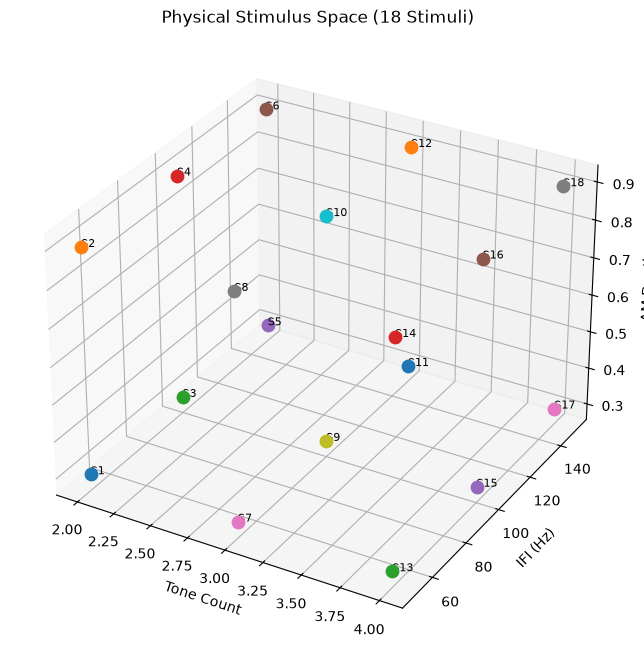

In [156]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

tone_counts = [2,3,4]
ifis = [50,100,150]
am_depths = [0.3,0.9]

points = []

stim_id = 1

for tone in tone_counts:
    for ifi in ifis:
        for am in am_depths:

            points.append(
                (stim_id, tone, ifi, am)
            )

            stim_id += 1

fig = plt.figure(figsize=(10,8))

ax = fig.add_subplot(
    111,
    projection='3d'
)

for stim_id, tone, ifi, am in points:

    ax.scatter(
        tone,
        ifi,
        am,
        s=80
    )

    ax.text(
        tone,
        ifi,
        am,
        f"S{stim_id}",
        fontsize=8
    )

ax.set_xlabel("Tone Count")
ax.set_ylabel("IFI (Hz)")
ax.set_zlabel("AM Depth")

ax.set_title(
    "Physical Stimulus Space (18 Stimuli)"
)

plt.show()

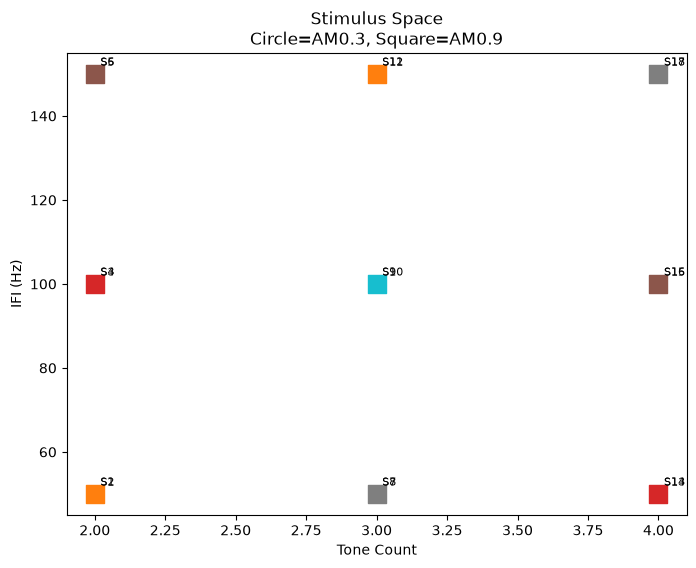

In [157]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    figsize=(8,6)
)

for stim_id, tone, ifi, am in points:

    marker = "o" if am == 0.3 else "s"

    ax.scatter(
        tone,
        ifi,
        s=150,
        marker=marker
    )

    ax.text(
        tone+0.02,
        ifi+2,
        f"S{stim_id}",
        fontsize=8
    )

ax.set_xlabel("Tone Count")
ax.set_ylabel("IFI (Hz)")
ax.set_title(
    "Stimulus Space\nCircle=AM0.3, Square=AM0.9"
)

plt.show()